07 one robust pipeline: putting the pieces together, with an honest val split and 3 seeds

notebooks 01-06 each tested one idea on its own. the ideas that held up were: **fix the border** (logit adjustment, notebook 01), **a balanced neutral-vs-rest head** as the one TG-MILNet part with a real ranking gain (notebook 06, not reproduced yet because my BAM had no balancing), and **don't bother with** strip weights (03), frame attention (04), GEI-subtract / flow / AGF (05), text, DTW bags and IBTA (06). here i put the surviving pieces into one pipeline and ablate them one by one.

"robust" is the goal, so here it means four concrete things, and every variant is judged on all four:

1. **no test tuning**: the border (`tau`) is chosen on a separate **val set** of children, never on test. in notebooks 01 and 06 the best tau was found on test (or with CV inside test).
2. **small spread over seeds**: every variant is trained with **3 seeds**, and i report mean +- std and the **worst seed**. none of the papers (ScoNet-MT, TG-MILNet, ScoliGaitX) report seeds.
3. **better ranking, not only a moved border**: the AUC (neutral vs negative, scoliosis vs negative, positive vs neutral) doesn't depend on the border, so a gain in AUC is a real gain in the features (like TG-MILNet over my curve), and a gain only in accuracy can be a border shift (like ScoliGaitX).
4. **stable to the test clips**: every child is tested with 3 different sets of random clips, to see how much of the spread comes from the test input alone.

new things i try here that no earlier notebook had: a **balanced BAM** (binary neutral-vs-rest head with a logit-adjusted binary loss), a **class-level triplet** (ScoNet-MT's triplet only uses the child id, so nothing pulls neutral children together), and **horizontal flip** as augmentation for the 20 minority children.

in step 1 i set things up, in step 2 i make three disjoint sets of children (train / val / test), in step 3 i write and check the new pieces, in step 4 i train the ablation ladder (5 variants x 3 seeds), in step 5 i choose tau on val and look at the main table, in step 6 i check robustness (seeds, test clips, matched Sen), in step 7 i look at the BAM branch on its own, and step 8 is the analysis.

step 1: setup

In [1]:
import sys
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

sys.path.insert(0, os.path.abspath(os.path.join('..', 'tools')))
from common import *

FIG_DIR = os.path.join('output', 'figures')
RUN_DIR = os.path.join('output', 'runs')
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(RUN_DIR, exist_ok=True)


def save_and_show(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, name), dpi=120)
    plt.show()


print('device:', DEVICE, torch.cuda.get_device_name(0) if DEVICE == 'cuda' else '')

device: cuda NVIDIA GeForce RTX 3050 Laptop GPU


here i load the same shared code as notebooks 01-06 (`tools/common.py`: data, ResNet9, ScoNet head, triplet, CE, `train_mini`, `predict_mini`, metrics). every trained run saves its scores to `output/runs/`, so if i run the notebook again it doesn't retrain, it just loads the scores. to retrain a variant i delete its `.npz` file.

step 2: three sets of children: train, val, test

in notebooks 01 and 06 there were only two sets, train (160 / 20 / 20) and test (40 / 40 / 40), so the border could only be chosen on test. here i add a **val set of 20 / 20 / 20 children** taken from the training split (`TRAIN_SET` of 1:1:8), but from children **not** in the mini train set, so the val children are new to the model like the test children. the train and test sets are exactly the same children as in notebooks 01 and 06 (same seed), so the numbers can be compared.

why 20 / 20 / 20 and not the natural 8 : 1 : 1? i choose the border by **balanced accuracy**, which needs enough children of every class, and 20 neutrals is already few (one neutral child = 5 points of neutral recall on val). the training split has 74 neutrals, 20 go to train, 20 to val, and 34 are not used.

In [2]:
split = load_split('118')
mini_train = load_items(pick_children(split['TRAIN_SET'], {'negative': 160, 'neutral': 20, 'positive': 20}, seed=0))
mini_test = load_items(pick_children(split['TEST_SET'], {'negative': 40, 'neutral': 40, 'positive': 40}, seed=0))

train_subjects = set(it['subject'] for it in mini_train)
rest_of_train = [s for s in split['TRAIN_SET'] if s not in train_subjects]
mini_val = load_items(pick_children(rest_of_train, {'negative': 20, 'neutral': 20, 'positive': 20}, seed=1))

val_subjects = set(it['subject'] for it in mini_val)
test_subjects = set(it['subject'] for it in mini_test)
print('children left in TRAIN_SET for val:', {c: len(v) for c, v in children_by_class(rest_of_train).items()})
print('train per class:', [sum(it['label'] == c for it in mini_train) for c in range(3)])
print('val   per class:', [sum(it['label'] == c for it in mini_val) for c in range(3)])
print('test  per class:', [sum(it['label'] == c for it in mini_test) for c in range(3)])
print('overlap train-val:', len(train_subjects & val_subjects), '| train-test:', len(train_subjects & test_subjects),
      '| val-test:', len(val_subjects & test_subjects))

mini_counts = np.array([sum(it['label'] == c for it in mini_train) for c in range(3)])
mini_prior = torch.tensor(mini_counts / mini_counts.sum(), dtype=torch.float32, device=DEVICE)
bam_prior = torch.tensor([1 - mini_prior[1].item(), mini_prior[1].item()], dtype=torch.float32, device=DEVICE)
LOG_PRIOR = np.log(mini_counts / mini_counts.sum())
print('train prior:', np.round(mini_counts / mini_counts.sum(), 3), '| BAM prior (not neutral, neutral):',
      np.round(bam_prior.cpu().numpy(), 3))

children left in TRAIN_SET for val: {'negative': 436, 'neutral': 54, 'positive': 54}
train per class: [160, 20, 20]
val   per class: [20, 20, 20]
test  per class: [40, 40, 40]
overlap train-val: 0 | train-test: 0 | val-test: 0


train prior: [0.8 0.1 0.1] | BAM prior (not neutral, neutral): [0.9 0.1]


the three sets are disjoint (overlap 0 / 0 / 0). after taking the 160 / 20 / 20 training children, the training split still has 436 / 54 / 54 children, and the val set takes 20 / 20 / 20 of them. the train prior is 0.8 / 0.1 / 0.1, so the LA loss adds `log(0.8, 0.1, 0.1)` and the balanced BAM adds `log(0.9, 0.1)`.

step 3: the new pieces

**logit-adjusted loss (LA, from notebook 01).** the CE is computed on `16 z + log(prior)` instead of `16 z`. during training the prior is "added for free", so the logits `z` themselves don't have to learn it, and at test time `argmax z` is already a balanced border. in notebook 01 it was the best mini fix (65.8%) and as good as weighted CE.

**balanced BAM.** a second branch after the backbone (own SeparateFCs + BNNeck, 2 classes: not neutral / neutral), like TG-MILNet. in notebook 06 my BAM had no balancing, and on 180 vs 20 children it collapsed like the main head (BAM AUC 0.771). here the binary CE gets the same logit adjustment: `16 b + log(0.9, 0.1)`. the decision stays the 3-class head (notebook 06: BAM as a hard rule steals positives), so BAM only shapes the backbone during training. in step 7 i still check if adding the BAM score to the neutral logit helps.

**class-level triplet.** ScoNet-MT's triplet uses the **child id**: anchor and positive are two clips of the same child. that teaches "who is this child", and nothing in it says "these two different neutral children belong together". so i add a second triplet where anchor and positive are **any two children of the same class** and the negative is a child of another class. the OpenGait triplet code (`triplet_loss` in common.py) needs the same number of positives per anchor (it reshapes with `.view`), which is true for child ids (always 2 copies) but not for classes in a natural batch (e.g. 15 negatives and 2 neutrals). so i write a **masked** version: compute all (anchor, positive, negative) combinations and keep only the valid ones with a mask. if a batch has only one class, there's no valid triplet and the loss is 0.

**horizontal flip.** a mirrored child with a curve to the left is still a child with scoliosis (a curve to the right), so the label stays the same. with only 20 neutral and 20 positive training children, every mirrored copy is "a new child" for the network. i put the flip inside `forward` (only in training mode, each clip has a 50% chance), so `train_mini` from common.py stays the same.

In [3]:
def class_triplet_loss(embed, labels, margin=0.2):
    # embed [n, c, p]; anchor + positive = same class (not the same item), negative = other class
    x = embed.permute(2, 0, 1).float()                                # [p, n, c]
    x2 = (x ** 2).sum(-1)
    dist = torch.sqrt(F.relu(x2.unsqueeze(2) + x2.unsqueeze(1) - 2 * x.matmul(x.transpose(1, 2))) + 1e-12)
    n = labels.shape[0]
    same = labels.unsqueeze(1) == labels.unsqueeze(0)                 # [n, n]
    eye = torch.eye(n, dtype=torch.bool, device=labels.device)
    pos_mask = same & ~eye
    neg_mask = ~same
    valid = pos_mask.unsqueeze(2) & neg_mask.unsqueeze(1)            # [n, n, n]: (anchor, positive, negative)
    loss = F.relu(dist.unsqueeze(3) - dist.unsqueeze(2) + margin) * valid.unsqueeze(0)
    loss = loss.view(loss.shape[0], -1)
    num = (loss > 0).sum(-1).float()
    avg = loss.sum(-1) / (num + 1e-9)
    return avg.mean()


class RobustNet(ScoNetMT):
    # ScoNet-MT + optional balanced BAM branch + optional flip augmentation (training only)
    def __init__(self, bam=False, flip=False):
        super().__init__()
        self.use_bam = bam
        self.flip = flip
        if bam:
            self.bam_fcs = SeparateFCs(16, 512, 256)
            self.bam_necks = SeparateBNNecks(16, 256, 2)
            init_parameters(self.bam_fcs)
            init_parameters(self.bam_necks)

    def forward(self, sils):
        if self.training and self.flip:
            mirror = torch.rand(sils.shape[0], device=sils.device) < 0.5
            shape = [-1] + [1] * (sils.dim() - 1)
            sils = torch.where(mirror.view(shape), sils.flip(-1), sils)
        f = encode_frames(self.backbone, sils).max(1)[0]
        strips = horizontal_pooling(f)
        embed = self.fcs(strips)
        out = {'embed': embed, 'logits': self.bnnecks(embed)}
        if self.use_bam:
            out['bam'] = self.bam_necks(self.bam_fcs(strips))          # [n, 2, 16]: 0 = not neutral, 1 = neutral
        return out


def make_loss(cfg):
    def loss_fn(out, labels, pids):
        logits = out['logits'].float()
        if cfg['la']:
            logits = logits + (torch.log(mini_prior) / 16).view(1, 3, 1)
        loss = triplet_loss(out['embed'], pids) + ce_loss(logits, labels)
        if cfg['bam']:
            b = out['bam'].float() + (torch.log(bam_prior) / 16).view(1, 2, 1)
            loss = loss + ce_loss(b, (labels == 1).long())
        if cfg['ctri']:
            loss = loss + class_triplet_loss(out['embed'], labels)
        return loss
    return loss_fn

In [4]:
# sanity checks of the new pieces
torch.manual_seed(0)
e = torch.randn(18, 256, 16)

labels = torch.tensor([0] * 15 + [1] * 2 + [2] * 1)
print('class triplet, 15 / 2 / 1 batch          :', round(class_triplet_loss(e, labels).item(), 4))
print('class triplet, only negatives in batch   :', round(class_triplet_loss(e, torch.zeros(18, dtype=torch.long)).item(), 4))
pull = e.clone()
pull[labels == 1] = pull[labels == 1].mean(0, keepdim=True)
pull[labels == 0] = pull[labels == 0].mean(0, keepdim=True) * 0 + 5
print('class triplet, classes already far apart :', round(class_triplet_loss(pull, labels).item(), 4))

m = RobustNet(bam=True, flip=True).to(DEVICE).train()
x = torch.rand(4, 16, 64, 44, device=DEVICE)
out = m(x)
print('outputs:', {k: tuple(v.shape) for k, v in out.items()})
print('loss of a random batch:', round(make_loss({'la': True, 'bam': True, 'ctri': True})(
    out, torch.tensor([0, 0, 1, 2], device=DEVICE), torch.tensor([0, 0, 1, 1], device=DEVICE)).item(), 4))

class triplet, 15 / 2 / 1 batch          : 1.0394
class triplet, only negatives in batch   : 0.0
class triplet, classes already far apart : 0.0


outputs: {'embed': (4, 256, 16), 'logits': (4, 3, 16), 'bam': (4, 2, 16)}


loss of a random batch: 2.5592


the class triplet behaves like it should: on a natural-looking batch (15 / 2 / 1) it gives a normal loss (1.04), with only negatives in the batch it gives **exactly 0** (no valid triplet, so no crash and no fake gradient), and when the classes are already far apart it's also 0 (every triplet already satisfies the margin). the model with BAM and flip returns the 3 outputs with the right shapes, and the full loss runs on a mixed batch.

step 4: the ablation ladder (5 variants x 3 seeds)

every variant adds **one** piece to the one before, so the difference between two neighbours is the effect of that piece (given the pieces before it):

| variant | loss | BAM | class triplet | flip |
|---|---|---|---|---|
| A ScoNet-MT | triplet(child) + CE | - | - | - |
| B + LA loss | triplet(child) + LA-CE | - | - | - |
| C + balanced BAM | B + LA binary CE | yes | - | - |
| D + class triplet | C + class triplet | yes | yes | - |
| E + flip | D, mirrored clips | yes | yes | yes |

the training is the mini setup of notebooks 01 and 06, unchanged: GaitBase init, 500 iterations, Adam (1e-4 backbone, 1e-3 everything new), 16 frames, **natural sampler** (9 random children, so 43% of the batches have no neutral, like the full training). the natural sampler is on purpose: notebook 01 showed that the balanced sampler memorises the 20 minority children, and a pipeline that only works with a special sampler isn't robust.

every run is tested on val (1 set of clips) and on test with **3 sets of clips** (clip seeds 0, 1, 2; 10 clips of 16 frames each, scores averaged). one run takes about 3-4 minutes on my laptop, so 15 runs take about an hour.

In [5]:
VARIANTS = {
    'A ScoNet-MT':       {'tag': 'A', 'la': False, 'bam': False, 'ctri': False, 'flip': False},
    'B + LA loss':       {'tag': 'B', 'la': True,  'bam': False, 'ctri': False, 'flip': False},
    'C + balanced BAM':  {'tag': 'C', 'la': True,  'bam': True,  'ctri': False, 'flip': False},
    'D + class triplet': {'tag': 'D', 'la': True,  'bam': True,  'ctri': True,  'flip': False},
    'E + flip':          {'tag': 'E', 'la': True,  'bam': True,  'ctri': True,  'flip': True},
}
SEEDS = [0, 1, 2]
CLIP_SEEDS = [0, 1, 2]


@torch.no_grad()
def predict_clips(model, items, out_key='logits', seed=0):
    # the same test as predict_mini (10 random clips of 16 frames, scores averaged over the clips),
    # but without the extra all-frames pass that predict_mini also does: i don't need it here and it costs time
    model = model.to(DEVICE).eval()
    rng = np.random.default_rng(seed)
    ys, scores = [], []
    for it in items:
        seq = it['seq']
        clips = np.stack([sil_transform(seq[np.sort(rng.choice(len(seq), MINI['frames'], replace=False))])
                          for _ in range(MINI['test_clips'])])
        with torch.autocast(device_type=DEVICE, enabled=DEVICE == 'cuda'):
            out = model(torch.tensor(clips).to(DEVICE))
        z = out[out_key].float().cpu().numpy().mean(-1)          # mean over strips -> [clips, classes]
        scores.append(z.mean(0))
        ys.append(it['label'])
    return np.array(ys), np.array(scores)


def run_variant(cfg, seed):
    path = os.path.join(RUN_DIR, f'{cfg["tag"]}_seed{seed}.npz')
    if os.path.exists(path):
        return dict(np.load(path))
    t0 = time.time()
    set_seed(seed)
    model = RobustNet(bam=cfg['bam'], flip=cfg['flip'])
    load_gaitbase_backbone(model.backbone)
    hist = train_mini(model, mini_train, loss_fn=make_loss(cfg), balanced=False, seed=seed, verbose=False)
    res = {'loss': np.array(hist['loss'])}
    y, s = predict_clips(model, mini_val, seed=0)
    res['y_val'], res['z_val'] = y, 16 * s
    for cs in CLIP_SEEDS:
        y, s = predict_clips(model, mini_test, seed=cs)
        res[f'z_test_c{cs}'] = 16 * s
    res['y_test'] = y
    if cfg['bam']:
        _, b = predict_clips(model, mini_val, out_key='bam', seed=0)
        res['bam_val'] = 16 * b
        _, b = predict_clips(model, mini_test, out_key='bam', seed=0)
        res['bam_test'] = 16 * b
    np.savez(path, **res)
    print(f'  trained in {time.time() - t0:.0f}s | last 50 iters loss {res["loss"][-50:].mean():.3f}')
    return res


runs = {}
for name, cfg in VARIANTS.items():
    for seed in SEEDS:
        print('---', name, '| seed', seed)
        runs[(name, seed)] = run_variant(cfg, seed)
print('done:', len(runs), 'runs')

--- A ScoNet-MT | seed 0


  trained in 222s | last 50 iters loss 0.633
--- A ScoNet-MT | seed 1


  trained in 216s | last 50 iters loss 0.640
--- A ScoNet-MT | seed 2


  trained in 209s | last 50 iters loss 0.599
--- B + LA loss | seed 0


  trained in 209s | last 50 iters loss 0.623
--- B + LA loss | seed 1


  trained in 205s | last 50 iters loss 0.619
--- B + LA loss | seed 2


... (6 outputs left out)

  trained in 229s | last 50 iters loss 1.100
--- E + flip | seed 0


  trained in 227s | last 50 iters loss 1.290
--- E + flip | seed 1


  trained in 207s | last 50 iters loss 1.261
--- E + flip | seed 2


  trained in 217s | last 50 iters loss 1.244
done: 15 runs


step 5: choose tau on val, then look at test

for every run i choose the border on **val** and apply it to test, without looking at test:

`adjusted z = 16 z - tau * log(train prior)`, with `tau` from -1 to 2 in steps of 0.05, and the best `tau` = highest **balanced accuracy on val** (ties: the tau closest to 0). tau can be negative, because an LA-trained model may already over-correct and then it has to go back.

i report test at **tau = 0** (plain argmax, what a paper without calibration would report) and at the **val tau**. the AUCs don't depend on tau (adding a constant per class doesn't change the ranking), so they're computed once per run:

- `auc_nn` = neutral vs negative on `z_neu - z_neg` (the hard pair: in my full model 97% of the missed neutrals go to negative),
- `auc_sn` = scoliosis (neutral + positive) vs negative on `max(z_neu, z_pos) - z_neg` (this is what Sen / Spe measure),
- `auc_pn` = positive vs neutral on `z_pos - z_neu`.

In [6]:
TAUS = np.round(np.arange(-1, 2.001, 0.05), 2)


def adjust(z, tau):
    return z - tau * LOG_PRIOR


def choose_tau(z_val, y_val):
    best_tau, best_bal = 0.0, -1.0
    for tau in sorted(TAUS, key=abs):                       # closest to 0 first, so ties keep the smaller tau
        bal = metrics(y_val, adjust(z_val, tau).argmax(1))['bal']
        if bal > best_bal + 1e-9:
            best_tau, best_bal = tau, bal
    return best_tau, best_bal


def pair_aucs(z, y):
    s_nn = z[:, 1] - z[:, 0]
    s_sn = np.maximum(z[:, 1], z[:, 2]) - z[:, 0]
    s_pn = z[:, 2] - z[:, 1]
    return {'auc_nn': 100 * auc(s_nn[y == 1], s_nn[y == 0]),
            'auc_sn': 100 * auc(s_sn[y > 0], s_sn[y == 0]),
            'auc_pn': 100 * auc(s_pn[y == 2], s_pn[y == 1])}


def evaluate_run(res, clip_seed=0):
    z_test, y_test = res[f'z_test_c{clip_seed}'], res['y_test']
    tau, val_bal = choose_tau(res['z_val'], res['y_val'])
    raw = metrics(y_test, z_test.argmax(1))
    cal = metrics(y_test, adjust(z_test, tau).argmax(1))
    cal.update(pair_aucs(z_test, y_test))
    cal['tau'], cal['val_bal'] = tau, val_bal
    return raw, cal


evals = {key: evaluate_run(res) for key, res in runs.items()}


def mean_std(values):
    return f'{np.mean(values):5.1f} +-{np.std(values):4.1f}'


def summary_table(which):
    keys = ['acc', 'Sen', 'Spe', 'rec_neu', 'rec_pos', 'bal']
    print(f'{"":20s}' + ''.join(f'{k:>13s}' for k in keys) + f'{"worst bal":>11s}')
    for name in VARIANTS:
        ms = [evals[(name, s)][which] for s in SEEDS]
        line = f'{name:20s}' + ''.join(f'{mean_std([m[k] for m in ms]):>13s}' for k in keys)
        print(line + f'{min(m["bal"] for m in ms):11.1f}')


print('test at tau = 0 (plain argmax), mean +- std over 3 seeds')
summary_table(0)
print()
print('test at the tau chosen on val, mean +- std over 3 seeds')
summary_table(1)
print()
print(f'{"":20s}{"auc_nn":>13s}{"auc_sn":>13s}{"auc_pn":>13s}   val taus')
for name in VARIANTS:
    ms = [evals[(name, s)][1] for s in SEEDS]
    print(f'{name:20s}' + ''.join(f'{mean_std([m[k] for m in ms]):>13s}' for k in ['auc_nn', 'auc_sn', 'auc_pn'])
          + '   ' + ', '.join(f'{m["tau"]:.2f}' for m in ms))

test at tau = 0 (plain argmax), mean +- std over 3 seeds
                              acc          Sen          Spe      rec_neu      rec_pos          bal  worst bal
A ScoNet-MT           35.6 +- 0.4 100.0 +- 0.0   3.3 +- 0.6   1.7 +- 1.2   5.0 +- 0.0  35.6 +- 0.4       35.0
B + LA loss           66.9 +- 2.4  77.5 +- 4.1  72.5 +- 4.1  55.8 +- 2.4  67.5 +- 3.5  66.9 +- 2.4       64.2
C + balanced BAM      67.5 +- 3.0  78.3 +- 4.7  71.7 +- 5.2  54.2 +- 2.4  70.0 +- 6.1  67.5 +- 3.0       63.3
D + class triplet     69.7 +- 2.7  77.5 +- 3.5  76.7 +- 3.1  56.7 +- 2.4  75.0 +- 3.5  69.7 +- 2.7       66.7
E + flip              61.1 +- 1.6  68.3 +- 6.6  71.2 +- 6.1  55.0 +- 3.5  60.0 +- 7.4  61.1 +- 1.6       60.0

test at the tau chosen on val, mean +- std over 3 seeds
                              acc          Sen          Spe      rec_neu      rec_pos          bal  worst bal
A ScoNet-MT           70.3 +- 2.7  69.2 +- 8.5  82.9 +- 8.7  65.0 +- 7.1  76.7 +- 8.2  70.3 +- 2.7       66.7
B + LA

**at tau = 0 the plain ScoNet-MT (A) collapses on all 3 seeds: 35.6 +- 0.4, everything negative** (Sen 100, neutral 1.7, positive 5.0), the same as notebook 01. every variant with the LA loss (B-E) is already usable without any calibration (61-70).

**but once tau is chosen on val, A, B, C and D are all the same: 70.3 / 68.9 / 69.4 / 69.2 balanced accuracy**, all within one std (2.7-4.1) of each other. the worst seed is 64-67 for all four. so on this mini setup, the val-chosen border on its own repairs the plain ScoNet-MT as well as the LA loss, BAM and class triplet together. the val taus tell the same story: A needs tau 1.0-1.3 (it learned the whole prior), the LA models need about 0 (-0.15 to 0.30), so the LA loss and the val tau are two ways of doing the same correction.

**the AUCs are flat: neutral vs negative 82.1 / 80.5 / 81.7 / 81.8 for A-D**, scoliosis vs negative 85.7-86.5, positive vs neutral 88.6-89.7. so none of the three additions (LA loss, balanced BAM, class triplet) improved the **ranking**. TG-MILNet's BAM gain was a ranking gain (above my curve, notebook 06), and in this setting my balanced BAM doesn't reproduce it.

**flip (E) clearly hurts: balanced 60.3 (-8.9 vs D), AUC neutral vs negative 73.5 (-8.3), scoliosis vs negative 75.9 (-10.6).** it's the only difference in this table that is many stds big, and it's the same direction on all 3 seeds. so mirroring the silhouette destroys information. my guess why: in adolescent idiopathic scoliosis most thoracic curves bend to the **right**, so "which side is higher / wider" is part of the signal, and a mirrored child is not a realistic child. i didn't test this guess directly (that needs the test children scored once normal and once mirrored).

one more detail: for B and D, the val tau is **not better than tau = 0** (B 66.9 -> 68.9, D 69.7 -> 69.2). with 20 children per class on val, choosing tau adds its own noise, so once the loss already balances the border, a val tau mostly moves the result around.

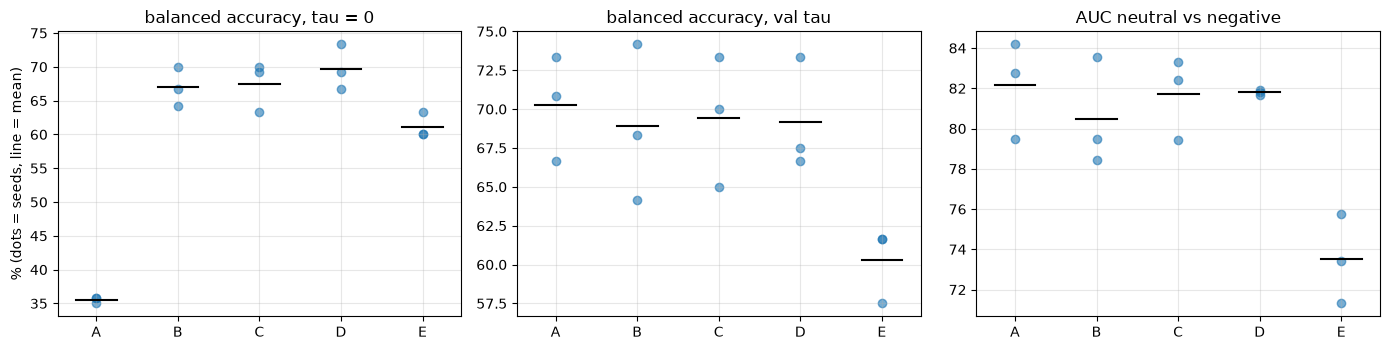

In [7]:
names = list(VARIANTS)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for i, name in enumerate(names):
    for j, (key, title, which) in enumerate([('bal', 'balanced accuracy, tau = 0', 0),
                                              ('bal', 'balanced accuracy, val tau', 1),
                                              ('auc_nn', 'AUC neutral vs negative', 1)]):
        vals = [evals[(name, s)][which][key] for s in SEEDS]
        ax[j].scatter([i] * len(vals), vals, color='tab:blue', alpha=0.6)
        ax[j].plot([i - 0.25, i + 0.25], [np.mean(vals)] * 2, color='black')
        ax[j].set_title(title)
for a in ax:
    a.set_xticks(range(len(names)), [n.split(' ')[0] for n in names])
    a.grid(alpha=0.3)
ax[0].set_ylabel('% (dots = seeds, line = mean)')
save_and_show(fig, '01_ladder_seeds.png')

the figure shows the same thing per seed: in the middle panel the dots of A-D overlap (64-74), E is lower on every seed. in the left panel only A is at 35 (collapsed without tau). in the right panel A-D are at 78-84 AUC and E at 71-76. and **seed 1 is the best seed for every one of A-D** (73.3-74.2 balanced), seed 0 the worst for A-C: the seed decides the order of the batches and the head init, and that matters more than which variant it is, so a single-seed comparison between two variants mostly compares seeds. the line (mean) of D in the AUC panel has almost no spread (81.8 +- 0.1), but with 3 seeds that's more likely luck than a real stabilising effect of the class triplet.

step 6: how robust is it? seeds, test clips, matched Sen

three checks:

1. **seed spread vs clip spread.** for every variant: the std of the balanced accuracy over the 3 training seeds (same test clips), and the std over the 3 test clip seeds (same model, then averaged over the 3 models). if the clip spread is about as big as the seed spread, a large part of the "seed noise" is just the test input.
2. **tau spread.** how far apart the 3 val-chosen taus are. a pipeline whose border is the same for every seed is easier to trust (and to report) than one that needs a very different tau every time.
3. **matched Sen.** for every run, i scan tau **on test** and take the best mean of neutral and positive recall with Sen (negative recall) >= 90. this one is test-tuned on purpose: it's the "curve" view of notebook 01 (which method is above the other at the same Sen), not a result.

In [8]:
def best_at_matched_sen(z, y, min_sen=90):
    best = np.nan
    for tau in TAUS:
        m = metrics(y, adjust(z, tau).argmax(1))
        if m['Sen'] >= min_sen:
            score = (m['rec_neu'] + m['rec_pos']) / 2
            best = score if np.isnan(best) else max(best, score)
    return best


print(f'{"":20s}{"seed std":>10s}{"clip std":>10s}{"tau range":>12s}{"neu+pos @Sen>=90":>20s}')
for name in VARIANTS:
    seed_bal = [evals[(name, s)][1]['bal'] for s in SEEDS]
    clip_stds = []
    matched = []
    for s in SEEDS:
        res = runs[(name, s)]
        clip_bal = [evaluate_run(res, cs)[1]['bal'] for cs in CLIP_SEEDS]
        clip_stds.append(np.std(clip_bal))
        matched.append(best_at_matched_sen(res['z_test_c0'], res['y_test']))
    taus = [evals[(name, s)][1]['tau'] for s in SEEDS]
    print(f'{name:20s}{np.std(seed_bal):10.1f}{np.mean(clip_stds):10.1f}{min(taus):6.2f}..{max(taus):<4.2f}'
          f'{mean_std(matched):>20s}')

                      seed std  clip std   tau range    neu+pos @Sen>=90
A ScoNet-MT                2.7       1.5  1.00..1.30         48.3 +- 3.1
B + LA loss                4.1       1.2  0.00..0.15         47.9 +- 4.1
C + balanced BAM           3.4       1.4  0.05..0.20         48.3 +- 3.9


D + class triplet          3.0       1.4 -0.15..0.30         47.9 +- 2.6
E + flip                   2.0       0.6 -0.10..0.20         38.3 +- 5.6


**the test clips explain about half of the seed spread.** the std of the balanced accuracy over training seeds is 2.0-4.1, and over test clip seeds (same model) it's 0.6-1.5. so with 40 children per class, even re-drawing the 10 test clips moves the result by ~1.5 points, and 2 of the ~3-4 points between seeds would be there even with a perfectly repeatable training.

**the tau spread is much smaller for the LA models**: A needs 1.00-1.30, B 0.00-0.15, C 0.05-0.20, D -0.15-0.30. in absolute terms that's a similar range (~0.3-0.45), but the LA models are always near 0, so they also work when there is no val set (tau = 0 gave 67-70 for B-D).

**at matched Sen (>= 90), A-D are the same: 47.9-48.3** mean of neutral and positive recall, and E is lower (38.3). this is the curve view of notebook 01: A-D lie on one curve, E below it.

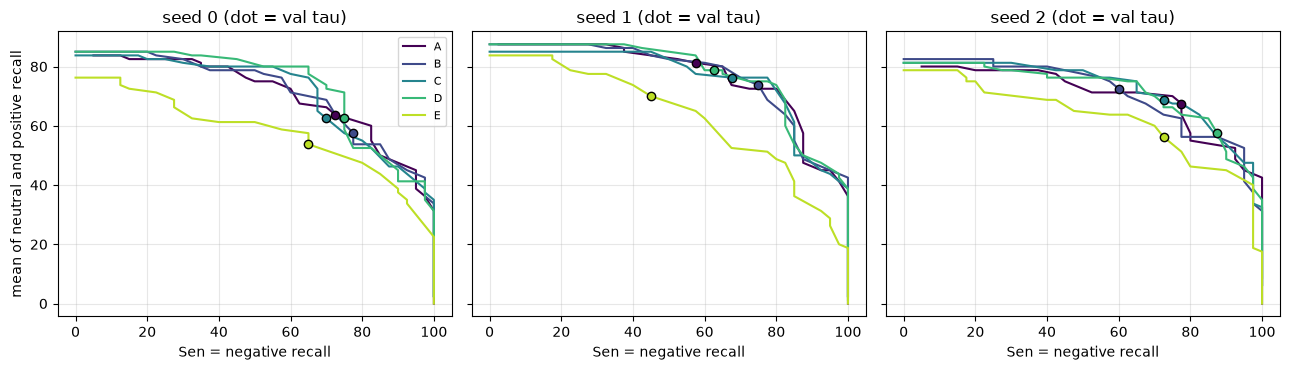

In [9]:
fig, ax = plt.subplots(1, len(SEEDS), figsize=(13, 3.8), sharey=True)
colors = plt.cm.viridis(np.linspace(0, 0.9, len(VARIANTS)))
for k, s in enumerate(SEEDS):
    for color, name in zip(colors, VARIANTS):
        res = runs[(name, s)]
        sen, spe = [], []
        for tau in TAUS:
            m = metrics(res['y_test'], adjust(res['z_test_c0'], tau).argmax(1))
            sen.append(m['Sen'])
            spe.append((m['rec_neu'] + m['rec_pos']) / 2)
        ax[k].plot(sen, spe, color=color, label=name.split(' ')[0] if k == 0 else None, lw=1.5)
        m = evals[(name, s)][1]
        ax[k].scatter(m['Sen'], (m['rec_neu'] + m['rec_pos']) / 2, color=color, edgecolor='black', zorder=3)
    ax[k].set_title(f'seed {s} (dot = val tau)')
    ax[k].set_xlabel('Sen = negative recall')
    ax[k].grid(alpha=0.3)
ax[0].set_ylabel('mean of neutral and positive recall')
ax[0].legend(fontsize=8)
save_and_show(fig, '02_tau_curves.png')

the curves confirm it on every seed: **A, B, C and D are on top of each other**, only the dot (where the val tau puts the border) moves along the same curve, and **E is under the others on all 3 seeds**. so the LA loss, BAM and class triplet change **where** the model sits on the curve, not the curve itself. that's exactly the "ScoliGaitX on my curve" situation from notebook 05, now with my own additions.

step 7: the BAM branch on its own

in variants C, D and E the BAM branch is trained but not used for the decision. here i check two things: **how well does the BAM branch rank neutral vs negative** (AUC of `b_neu - b_not`), compared with the 3-class head of the same model, and **does it help to add it to the neutral logit**: `z_neu + beta * (b_neu - b_not)`, with `beta` in {0, 0.25, 0.5, 1} and `tau` chosen together on val (beta = 0 is the normal 3-class decision, so val can always fall back to it).

In [10]:
BETAS = [0, 0.25, 0.5, 1.0]


def fuse(z, b, beta):
    z = z.copy()
    z[:, 1] = z[:, 1] + beta * (b[:, 1] - b[:, 0])
    return z


print(f'{"":20s}{"BAM auc_nn":>13s}{"head auc_nn":>13s}{"bal no fuse":>13s}{"bal fused":>13s}   val betas')
for name, cfg in VARIANTS.items():
    if not cfg['bam']:
        continue
    bam_auc, head_auc, bal_plain, bal_fused, betas = [], [], [], [], []
    for s in SEEDS:
        res = runs[(name, s)]
        y = res['y_test']
        b = res['bam_test']
        sb = b[:, 1] - b[:, 0]
        bam_auc.append(100 * auc(sb[y == 1], sb[y == 0]))
        head_auc.append(evals[(name, s)][1]['auc_nn'])
        bal_plain.append(evals[(name, s)][1]['bal'])
        best = (-1, 0, 0)
        for beta in BETAS:
            tau, vb = choose_tau(fuse(res['z_val'], res['bam_val'], beta), res['y_val'])
            if vb > best[0] + 1e-9:
                best = (vb, beta, tau)
        _, beta, tau = best
        betas.append(beta)
        bal_fused.append(metrics(y, adjust(fuse(res['z_test_c0'], b, beta), tau).argmax(1))['bal'])
    print(f'{name:20s}{mean_std(bam_auc):>13s}{mean_std(head_auc):>13s}{mean_std(bal_plain):>13s}'
          f'{mean_std(bal_fused):>13s}   {betas}')

                       BAM auc_nn  head auc_nn  bal no fuse    bal fused   val betas
C + balanced BAM      78.9 +- 1.0  81.7 +- 1.7  69.4 +- 3.4  69.4 +- 3.4   [0, 0, 0]
D + class triplet     80.0 +- 1.0  81.8 +- 0.1  69.2 +- 3.0  69.2 +- 3.0   [0, 0, 0]
E + flip              72.9 +- 1.5  73.5 +- 1.8  60.3 +- 2.0  59.2 +- 1.8   [0.25, 0.5, 0.25]


**the balanced BAM branch ranks neutral vs negative a bit worse than the 3-class head of the same model** (78.9 vs 81.7 in C, 80.0 vs 81.8 in D), so it learned less about neutral than the main head, not more. in notebook 06 the unbalanced BAM had AUC 77.1, so the balancing helped the branch itself a little (+1.8 to +2.9), but not enough to add anything.

**val never wanted to fuse it for C and D (beta = 0 on all 6 runs)**, so the result with fusion is the same as without. in E val chose beta 0.25-0.5, and the test got slightly worse (60.3 -> 59.2). so the BAM score is useless as a decision too, which matches the decision-level test in notebook 06.

step 8: analysis

**1. which pieces made the pipeline better?**

none, in this mini setting. with tau chosen on val, A (plain ScoNet-MT) 70.3, B (+ LA) 68.9, C (+ balanced BAM) 69.4, D (+ class triplet) 69.2 balanced accuracy, all within one std (2.7-4.1), and the AUCs are all 80.5-82.1. the only effect bigger than the noise is negative: flip costs 8.9 balanced accuracy and 8.3 AUC.

**2. what does the LA loss give, if not accuracy?**

it gives a model that works **without calibration**: at tau = 0, A collapses (35.6) and B-D get 67-70, and the val tau of the LA models is always near 0 (-0.15-0.30, vs 1.0-1.3 for A). so LA and a val tau are the same correction, done in training or after it. for a robust pipeline that's still useful: if the val set is small or shifted, LA is safer than a big tau.

**3. why didn't balanced BAM reproduce TG-MILNet's gain?**

the BAM branch itself ranks neutral vs negative worse than the main head (78.9-80.0 vs 81.7-81.8), and val never wanted to use it. possible reasons: only 20 neutral children and 500 iterations (TG-MILNet has 74 neutrals and full training), a natural sampler where 43% of the batches have no neutral at all (no BAM gradient in those batches), and maybe their gain needs the other parts too (bags, 128 x 88 input). so it's "not reproduced in a small setting", not "BAM is useless", the same verdict as notebook 06, now also with balancing.

**4. why didn't the class triplet help?**

with a natural batch of 9 children, most batches have 0-2 neutral children, so most class triplets are negative-vs-positive or negative-vs-negative anchors, and the neutral-vs-negative pair (the one that matters) is rare. its loss (last 50 iterations 1.10-1.18 vs 0.86-0.90 for C) shows it was active, but the AUC didn't move. it might need a sampler that guarantees at least 1-2 neutrals per batch.

**5. why does flip hurt so much?**

it's the one big effect (-8.9 balanced, -8.3 AUC, all 3 seeds). my hypothesis is that left / right asymmetry is part of the signal (most idiopathic thoracic curves bend to the right), so mirroring makes unrealistic children and teaches the model to ignore the side. this is a hypothesis, not tested here.

**6. how robust are the numbers themselves?**

the seed std is 2.0-4.1 balanced accuracy, and the test clips alone give 0.6-1.5 of that, with 40 children per class. so a difference under ~5 points between two variants can't be trusted in this setup, and the same is probably true for the papers, which report one run each.

**7. what are the limitations?**

- mini setting: 160 / 20 / 20 training children, 500 iterations, GaitBase init, 16 frames. small gains (+1-3) that might show up at full scale are invisible here.
- 3 seeds and 40 test children per class: one neutral child = 2.5 points of neutral recall.
- the val set has only 20 children per class, so the val tau itself is noisy (B and D were better at tau = 0 than at the val tau).
- the ladder adds pieces in one order, so an effect of BAM *without* LA, or of the class triplet without BAM, is not measured.
- the class triplet ran with the natural sampler, where neutral-vs-negative triplets are rare.
- the flip explanation (right-sided curves) is a hypothesis, not tested.
- the BAM weight (1) and class triplet weight (1) and margin (0.2) were not tuned.

what can we absorb into the new architecture?

the honest result of this notebook is that **the robust part of the pipeline is the border, not a new module**: plain ScoNet-MT + a tau chosen on val is as good as everything i added on top (70.3 balanced, A-D within noise), and all of A-D lie on one Sen / Spe curve. so for the full-scale pipeline in `exp_1` i keep **LA loss + val-tuned tau** (LA because it doesn't collapse without calibration and its tau stays near 0), and **drop horizontal flip** (the one clear negative result, -8.9).

BAM and the class triplet are **not proven, not disproven**: they're cheap, they didn't hurt (69.4 / 69.2 vs 68.9), and their possible benefit needs more neutrals than 20. so they go into `exp_1` as ablations at full scale (A vs B vs C vs D, 3 seeds each), not into the main pipeline yet. if they still sit on the same curve there, they are dropped.

for the paper, this notebook gives a strong methodological point: **with a val-tuned border and 3 seeds, three "improvements" that look like gains at tau = 0 (B-D 67-70 vs A 35.6) disappear completely**, and the test clips alone explain about half of the seed spread. that is the kind of check none of ScoNet-MT, TG-MILNet or ScoliGaitX report, and it's how i'll judge any new module from now on: **AUC and the Sen / Spe curve first, accuracy second**.